In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
import seaborn as sns

In [2]:
data = np.load('./Provided Code/species_train.npz')
train_locs = data['train_locs']  # 2D array, rows are number of datapoints and 
                                 # columns are "latitude" and "longitude"
train_ids = data['train_ids']    # 1D array, entries are the ID of the species 
                                 # that is present at the corresponding location in train_locs
species = data['taxon_ids']      # list of species IDe. Note these do not necessarily start at 0 (or 1)
species_names = dict(zip(data['taxon_ids'], data['taxon_names']))  # latin names of species 

# loading test data 
data_test = np.load('./Provided Code/species_test.npz', allow_pickle=True)
test_locs = data_test['test_locs']    # 2D array, rows are number of datapoints 
                                      # and columns are "latitude" and "longitude"
# data_test['test_pos_inds'] is a list of lists, where each list corresponds to 
# the indices in test_locs where a given species is present, it can be assumed 
# that they are not present in the other locations 
test_pos_inds = dict(zip(data_test['taxon_ids'], data_test['test_pos_inds'])) 

# data stats
print('Train Stats:')
print('Number of species in train set:           ', len(species))
print('Number of train locations:                ', train_locs.shape[0])
_, species_counts = np.unique(train_ids, return_counts=True)
print('Average number of locations per species:  ', species_counts.mean())
print('Minimum number of locations for a species:', species_counts.min())
print('Maximum number of locations for a species:', species_counts.max())

Train Stats:
Number of species in train set:            500
Number of train locations:                 272037
Average number of locations per species:   544.074
Minimum number of locations for a species: 50
Maximum number of locations for a species: 2000


In [3]:
print(train_locs.shape)
print(train_ids.shape)

(272037, 2)
(272037,)


In [4]:
X = train_locs.copy()
y = train_ids.copy()

In [10]:
test_locs[test_pos_inds[31529]]

array([[-19.884237, 126.05298 ],
       [-20.219316, 124.72395 ],
       [-20.05369 , 125.386505],
       ...,
       [-20.684927, 116.9345  ],
       [-21.144205, 116.4734  ],
       [-23.751123, 113.715065]], shape=(784, 2), dtype=float32)

# 1st Expeeriment
## DecisionTree
- No parameters
- No defined limits
- Just Whats in the sklearn

In [5]:
clf = tree.DecisionTreeClassifier()
clf = clf.fit(X, y)

In [28]:
X_test = test_locs[test_pos_inds[31529]]
y_test = np.full(len(X_test),31529)
acc_1 = clf.score(X_test, y_test)
print(f"{acc_1*100:.2f}%")

6.25%


In [24]:
pred = clf.predict(X_test)

C:\Users\idg20\AppData\Local\Temp\ipykernel_9156\3460195845.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  pred_pd.rename({0:"predict"}, axis=1, inplace=True)


<Axes: xlabel='predict', ylabel='count'>

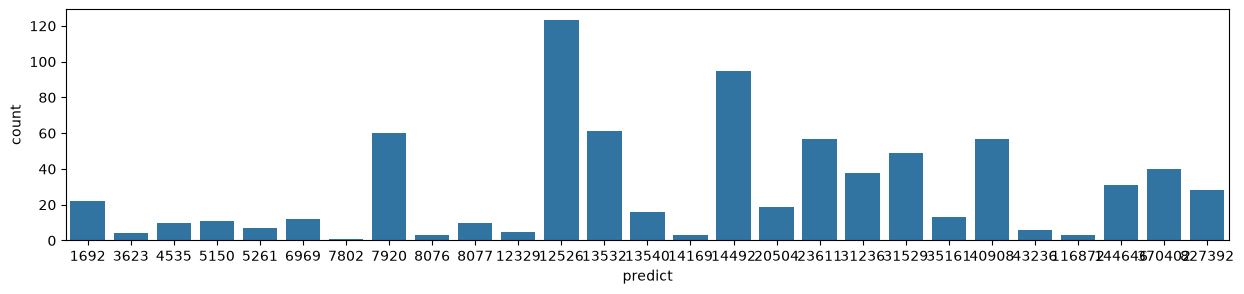

In [57]:
pred_pd = pd.DataFrame(pred)
pred_pd.rename({0:"predict"}, axis=1, inplace=True)
plt.figure(figsize=(15,3))
sns.countplot(pred_pd, x="predict")

# 2nd Experiment
## DecisionTree

- Using Entropy to for splits


In [25]:
clf_2 = tree.DecisionTreeClassifier(criterion='entropy')
clf_2 = clf_2.fit(X, y)

In [29]:
X_test = test_locs[test_pos_inds[31529]]
y_test = np.full(len(X_test),31529)
acc_2 = clf_2.score(X_test, y_test)
print(f"{acc_2*100:.2f}%")

4.72%


In [31]:
pred_2 = clf_2.predict(X_test)

C:\Users\idg20\AppData\Local\Temp\ipykernel_9156\680077535.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  pred2_pd.rename({0:"predict"}, axis=1, inplace=True)


<Axes: xlabel='predict', ylabel='count'>

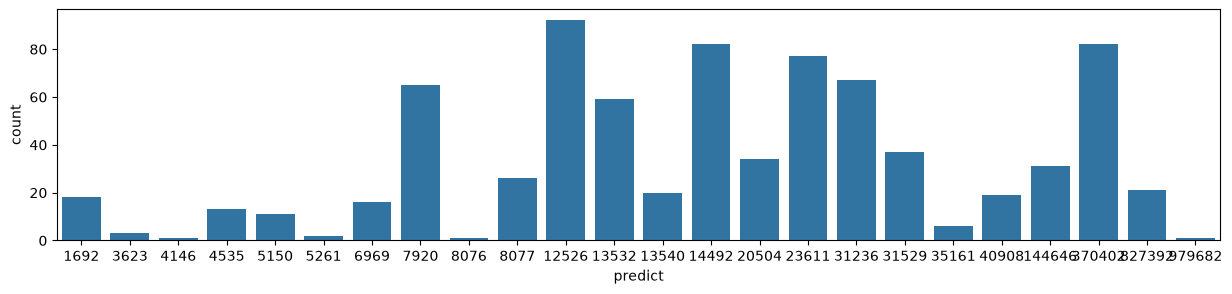

In [58]:
pred2_pd = pd.DataFrame(pred_2)
pred2_pd.rename({0:"predict"}, axis=1, inplace=True)
plt.figure(figsize=(15,3))
sns.countplot(pred2_pd, x="predict")

# 3rd Experiment
## Decision
- Using Entropy
- Max depth = num of species

In [34]:
clf_3 = tree.DecisionTreeClassifier(criterion='entropy', max_depth=500)
clf_3 = clf_3.fit(X, y)

In [36]:
pred_3 = clf_3.predict(X_test)

In [35]:
X_test = test_locs[test_pos_inds[31529]]
y_test = np.full(len(X_test),31529)
acc_3 = clf_3.score(X_test, y_test)
print(f"{acc_3*100:.2f}%")

4.85%


C:\Users\idg20\AppData\Local\Temp\ipykernel_9156\42487301.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  pred3_pd.rename({0:"predict"}, axis=1, inplace=True)


<Axes: xlabel='predict', ylabel='count'>

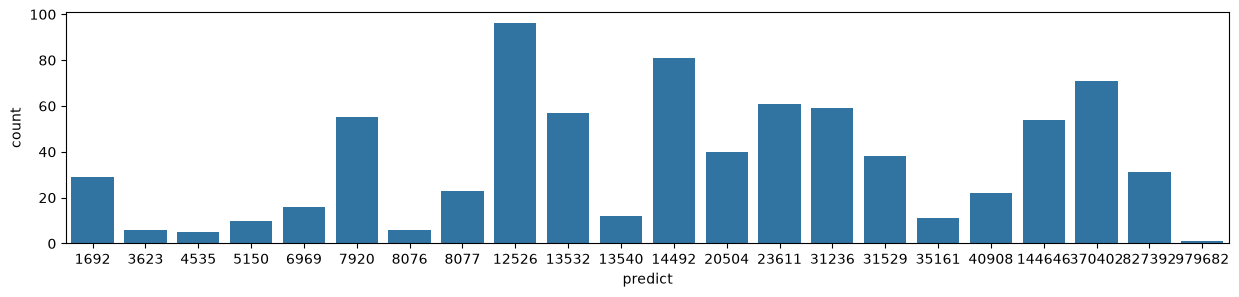

In [59]:
pred3_pd = pd.DataFrame(pred_3)
pred3_pd.rename({0:"predict"}, axis=1, inplace=True)
plt.figure(figsize=(15,3))
sns.countplot(pred3_pd, x="predict")

# 4th Experiment
## DT
- Use entropy
- Max leaf = num of species

In [67]:
clf_4 = tree.DecisionTreeClassifier(criterion='entropy', max_leaf_nodes=500)
clf_4 = clf_4.fit(X, y)

In [72]:
X_test = test_locs[test_pos_inds[31529]]
y_test = np.full(len(X_test),31529)
acc_4 = clf_4.score(X_test, y_test)
print(f"{acc_4*100:.2f}%")
pred_4 = clf_4.predict(X_test)

0.00%


C:\Users\idg20\AppData\Local\Temp\ipykernel_9156\2621171988.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  pred4_pd.rename({0:"predict"}, axis=1, inplace=True)


<Axes: xlabel='predict', ylabel='count'>

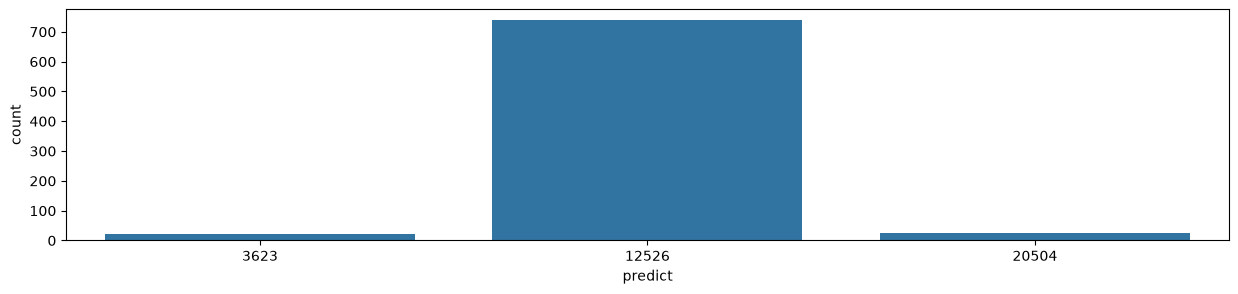

In [73]:
pred4_pd = pd.DataFrame(pred_4)
pred4_pd.rename({0:"predict"}, axis=1, inplace=True)
plt.figure(figsize=(15,3))
sns.countplot(pred4_pd, x="predict")

---

# Plot Tree
## !! Only run once !!

In [1]:
tree.plot_tree(clf_2)

NameError: name 'tree' is not defined

In [ ]:
tree.plot_tree(clf_3)

[Text(0.48702699722488346, 0.9852941176470589, 'x[1] <= -27.5\nentropy = 8.118\nsamples = 272037\nvalue = [270.0, 448.0, 1241.0, 81.0, 53.0, 103.0, 2000.0, 540.0\n65.0, 60.0, 320.0, 359.0, 449.0, 722.0, 234.0, 222.0\n1713.0, 71.0, 65.0, 545.0, 1324.0, 58.0, 2000.0, 117.0\n945.0, 875.0, 297.0, 430.0, 106.0, 2000.0, 61.0, 2000.0\n541.0, 703.0, 710.0, 50.0, 2000.0, 116.0, 2000.0, 2000.0\n388.0, 233.0, 150.0, 155.0, 1004.0, 1109.0, 343.0, 222.0\n255.0, 135.0, 660.0, 304.0, 120.0, 93.0, 62.0, 431.0\n346.0, 73.0, 68.0, 172.0, 1798.0, 137.0, 895.0, 360.0\n331.0, 81.0, 207.0, 608.0, 2000.0, 2000.0, 55.0, 489.0\n410.0, 390.0, 79.0, 90.0, 1615.0, 52.0, 184.0, 282.0\n57.0, 153.0, 2000.0, 213.0, 199.0, 108.0, 2000.0, 111.0\n100.0, 77.0, 58.0, 2000.0, 2000.0, 2000.0, 188.0, 533.0\n102.0, 349.0, 125.0, 2000.0, 157.0, 99.0, 2000.0, 2000.0\n147.0, 395.0, 113.0, 2000.0, 2000.0, 2000.0, 969.0\n1434.0, 273.0, 135.0, 85.0, 123.0, 631.0, 2000.0, 880.0\n2000.0, 2000.0, 138.0, 152.0, 93.0, 1423.0, 1018.0\n85

Error in callback <function _draw_all_if_interactive at 0x00000232E49E3100> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [ ]:
tree.plot_tree(clf_4)

[Text(0.5133818517981439, 0.9666666666666667, 'x[1] <= -27.5\nentropy = 8.118\nsamples = 272037\nvalue = [270.0, 448.0, 1241.0, 81.0, 53.0, 103.0, 2000.0, 540.0\n65.0, 60.0, 320.0, 359.0, 449.0, 722.0, 234.0, 222.0\n1713.0, 71.0, 65.0, 545.0, 1324.0, 58.0, 2000.0, 117.0\n945.0, 875.0, 297.0, 430.0, 106.0, 2000.0, 61.0, 2000.0\n541.0, 703.0, 710.0, 50.0, 2000.0, 116.0, 2000.0, 2000.0\n388.0, 233.0, 150.0, 155.0, 1004.0, 1109.0, 343.0, 222.0\n255.0, 135.0, 660.0, 304.0, 120.0, 93.0, 62.0, 431.0\n346.0, 73.0, 68.0, 172.0, 1798.0, 137.0, 895.0, 360.0\n331.0, 81.0, 207.0, 608.0, 2000.0, 2000.0, 55.0, 489.0\n410.0, 390.0, 79.0, 90.0, 1615.0, 52.0, 184.0, 282.0\n57.0, 153.0, 2000.0, 213.0, 199.0, 108.0, 2000.0, 111.0\n100.0, 77.0, 58.0, 2000.0, 2000.0, 2000.0, 188.0, 533.0\n102.0, 349.0, 125.0, 2000.0, 157.0, 99.0, 2000.0, 2000.0\n147.0, 395.0, 113.0, 2000.0, 2000.0, 2000.0, 969.0\n1434.0, 273.0, 135.0, 85.0, 123.0, 631.0, 2000.0, 880.0\n2000.0, 2000.0, 138.0, 152.0, 93.0, 1423.0, 1018.0\n857